# AIDA CellTypist Bias — Cross-Ethnicity Summary Analysis
Aggregates dose-response results from all 7 AIDA ethnic cohorts and produces comparative visualisations.

In [1]:
# ── Cell 1: Colab Setup ──────────────────────────────────────────────────────
!pip install -q scanpy celltypist
!pip uninstall -y cuml cudf 2>/dev/null; echo 'env ready'

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/aida-celltypist-bias'
os.chdir(PROJECT)
print('Working directory:', os.getcwd())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
env ready
Mounted at /content/drive
Working directory: /content/drive/MyDrive/aida-celltypist-bias


In [2]:
# ── Cell 2: Imports ──────────────────────────────────────────────────────────
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.lines import Line2D

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
# ── Cell 3: Load All Results ─────────────────────────────────────────────────
ETHNICITIES = {
    'sg_chinese':        'SG Chinese',
    'japanese':          'Japanese',
    'korean':            'Korean',
    'thai':              'Thai',
    'indian':            'Indian',
    'singaporean_malay': 'Singaporean Malay',
    'singaporean_indian':'Singaporean Indian',
}

PROJECT = '/content/drive/MyDrive/aida-celltypist-bias'
SAVE_DIR = f'{PROJECT}/outputs/summary'
os.makedirs(SAVE_DIR, exist_ok=True)

data   = {}   # key → DataFrame
status = []   # summary rows

for key, label in ETHNICITIES.items():
    csv_path = f'{PROJECT}/outputs/{key}/results_full_curve_{key}.csv'
    if not os.path.exists(csv_path):
        print(f'[MISSING] {label}: {csv_path}')
        status.append({'ethnicity': label, 'rounds': 0,
                       'proportions_covered': '-', 'f1_at_0pct': '-', 'f1_at_max': '-',
                       'delta_f1': '-', 'status': 'missing'})
        continue

    df = pd.read_csv(csv_path)
    data[key] = df

    n_rounds   = df['repeat'].nunique()
    props      = sorted(df['proportion'].unique())
    mean_f1    = df.groupby('proportion')['f1'].mean()
    f1_0       = mean_f1.get(0.0, np.nan)
    f1_max     = mean_f1.iloc[-1]
    delta      = f1_max - f1_0

    status.append({
        'ethnicity':          label,
        'rounds':             n_rounds,
        'proportions_covered': ', '.join(f'{p:.0%}' for p in props),
        'f1_at_0pct':         f'{f1_0:.4f}',
        'f1_at_max':          f'{f1_max:.4f}',
        'delta_f1':           f'{delta:+.4f}',
        'status':             'ok',
    })
    print(f'[OK] {label:22s}  rounds={n_rounds:3d}  F1: {f1_0:.4f} → {f1_max:.4f}  (Δ{delta:+.4f})')

df_status = pd.DataFrame(status)
print('\n', df_status.to_string(index=False))

[OK] SG Chinese              rounds= 36  F1: 0.8112 → 0.8223  (Δ+0.0111)
[OK] Japanese                rounds= 18  F1: 0.7991 → 0.8193  (Δ+0.0203)
[OK] Korean                  rounds= 16  F1: 0.8076 → 0.8191  (Δ+0.0115)
[OK] Thai                    rounds= 16  F1: 0.7817 → 0.8064  (Δ+0.0247)
[OK] Indian                  rounds=  8  F1: 0.0915 → 0.1714  (Δ+0.0800)
[OK] Singaporean Malay       rounds=  8  F1: 0.8005 → 0.8218  (Δ+0.0213)
[OK] Singaporean Indian      rounds=  8  F1: 0.7972 → 0.8092  (Δ+0.0121)

          ethnicity  rounds                                   proportions_covered f1_at_0pct f1_at_max delta_f1 status
        SG Chinese      36 0%, 10%, 20%, 30%, 40%, 50%, 60%, 70%, 80%, 90%, 100%     0.8112    0.8223  +0.0111     ok
          Japanese      18 0%, 10%, 20%, 30%, 40%, 50%, 60%, 70%, 80%, 90%, 100%     0.7991    0.8193  +0.0203     ok
            Korean      16 0%, 10%, 20%, 30%, 40%, 50%, 60%, 70%, 80%, 90%, 100%     0.8076    0.8191  +0.0115     ok
              T

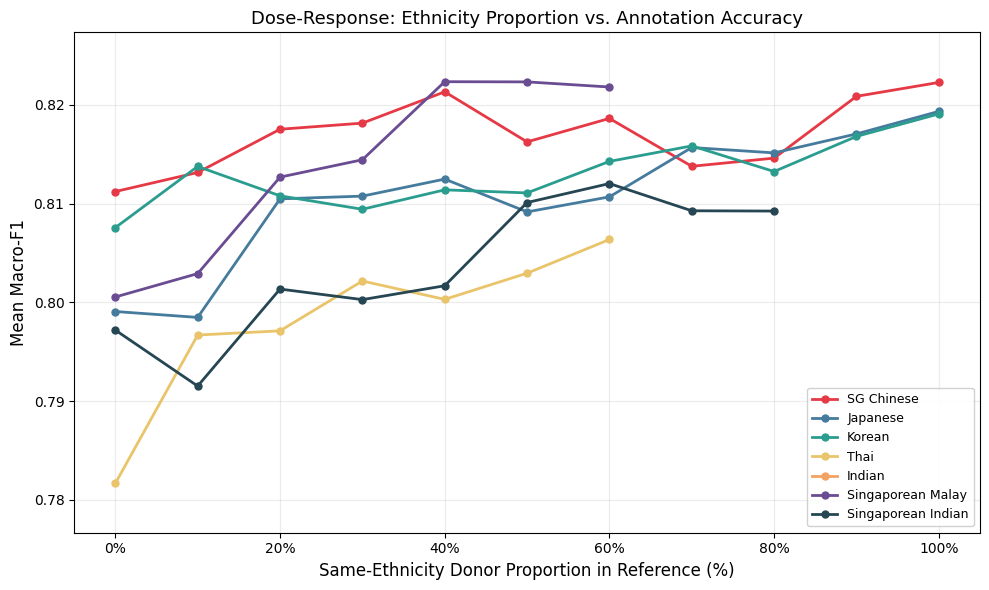

In [4]:
# ── Cell 4: Comparative Dose-Response Curve ──────────────────────────────────
import numpy as np

palette = {
    'sg_chinese':        '#E63946',
    'japanese':          '#457B9D',
    'korean':            '#2A9D8F',
    'thai':              '#E9C46A',
    'indian':            '#F4A261',
    'singaporean_malay': '#6A4C93',
    'singaporean_indian':'#264653',
}

fig, ax = plt.subplots(figsize=(10, 6))

for key, label in ETHNICITIES.items():
    if key not in data:
        continue
    grp  = data[key].groupby('proportion')['f1']
    mean = grp.mean()
    sem  = grp.sem()
    x    = mean.index * 100
    c    = palette[key]
    ax.plot(x, mean.values, marker='o', color=c, label=label,
            linewidth=2, markersize=5, zorder=3)


# y-axis: focus on main cluster, ignore outliers
all_vals = np.concatenate([
    data[k].groupby('proportion')['f1'].mean().values
    for k in data
])
y_lo = data['thai'].groupby('proportion')['f1'].mean().min() - 0.005
ax.set_ylim(y_lo, all_vals.max() + 0.005)

ax.set_xlabel('Same-Ethnicity Donor Proportion in Reference (%)', fontsize=12)
ax.set_ylabel('Mean Macro-F1', fontsize=12)
ax.set_title('Dose-Response: Ethnicity Proportion vs. Annotation Accuracy', fontsize=13)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(loc='lower right', fontsize=9, framealpha=0.9)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/dose_response_all_ethnicities.png', dpi=150)
plt.show()

In [5]:
# ── Cell 5: Notable Cell Types per Ethnicity (|ΔF1| > 0.03) ──────────────────
DELTA_THRESH = 0.03

notable_rows = []

for key, label in ETHNICITIES.items():
    json_path = f'{PROJECT}/outputs/{key}/all_reports_{key}.json'
    if not os.path.exists(json_path):
        continue

    with open(json_path) as fh:
        reports = json.load(fh)

    # average per-cell-type F1 across repeats for each proportion
    from collections import defaultdict
    ct_f1 = defaultdict(lambda: defaultdict(list))   # ct_f1[prop][celltype]
    for entry in reports:
        prop = entry['proportion']
        rep  = entry.get('report', {})
        for ct, metrics in rep.items():
            if isinstance(metrics, dict) and 'f1-score' in metrics:
                ct_f1[prop][ct].append(metrics['f1-score'])

    if not ct_f1:
        continue

    props = sorted(ct_f1.keys())
    p0, p1 = props[0], props[-1]

    ct_mean0 = {ct: np.mean(v) for ct, v in ct_f1[p0].items()}
    ct_mean1 = {ct: np.mean(v) for ct, v in ct_f1[p1].items()}

    all_ct = set(ct_mean0) & set(ct_mean1)
    for ct in all_ct:
        delta = ct_mean1[ct] - ct_mean0[ct]
        if abs(delta) >= DELTA_THRESH:
            notable_rows.append({
                'ethnicity': label,
                'cell_type': ct,
                'f1_0pct':   round(ct_mean0[ct], 4),
                'f1_max':    round(ct_mean1[ct], 4),
                'delta_f1':  round(delta, 4),
            })

df_notable = pd.DataFrame(notable_rows).sort_values(['ethnicity','delta_f1'])
df_notable.to_csv(f'{SAVE_DIR}/notable_celltypes_all.csv', index=False)
print(df_notable.to_string(index=False))

         ethnicity                                       cell_type  f1_0pct  f1_max  delta_f1
            Indian                                       macro avg   0.0915  0.1714    0.0800
            Indian                                        platelet   0.8751  0.9594    0.0842
            Indian                                    myeloid cell   0.4227  0.8934    0.4707
            Indian                             natural killer cell   0.2997  0.7926    0.4929
            Indian                                    weighted avg   0.3152  0.8705    0.5554
            Indian                                          B cell   0.3498  0.9421    0.5923
            Indian                                          T cell   0.2812  0.8820    0.6008
          Japanese                 pre-conventional dendritic cell   0.6736  0.6055   -0.0681
          Japanese                         hematopoietic stem cell   0.7630  0.7294   -0.0336
          Japanese          CD8-positive, alpha-beta memory 

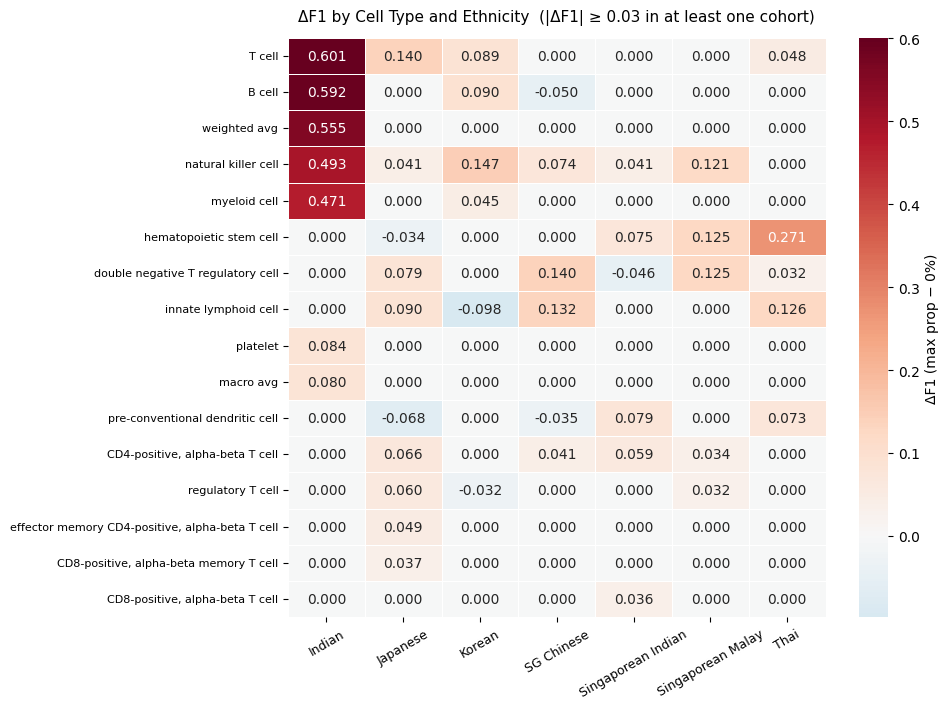

Saved.


In [6]:
# ── Cell 6: ΔF1 Heatmap — Notable Cell Types × Ethnicity ─────────────────────
if df_notable.empty:
    print('No notable cell types found (|ΔF1| >= 0.03).')
else:
    pivot = df_notable.pivot_table(
        index='cell_type', columns='ethnicity', values='delta_f1', fill_value=0
    )
    # keep only cell types notable in ≥1 ethnicity (already filtered), sort by mean abs delta
    pivot = pivot.loc[pivot.abs().max(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(max(8, len(pivot.columns)*1.4), max(5, len(pivot)*0.45)))
    sns.heatmap(
        pivot, annot=True, fmt='.3f', center=0,
        cmap='RdBu_r', linewidths=0.4,
        cbar_kws={'label': 'ΔF1 (max prop − 0%)'},
        ax=ax
    )
    ax.set_title('ΔF1 by Cell Type and Ethnicity  (|ΔF1| ≥ 0.03 in at least one cohort)',
                 fontsize=11, pad=12)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=9)
    ax.tick_params(axis='y', labelsize=8)
    fig.tight_layout()
    fig.savefig(f'{SAVE_DIR}/heatmap_delta_f1_all_ethnicities.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved.')

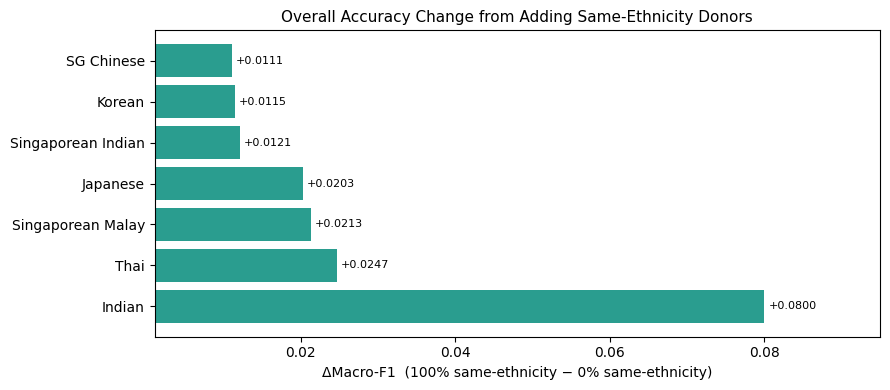

Saved.


In [7]:
# ── Cell 7: ΔF1 Bar Chart — Per Ethnicity ────────────────────────────────────
df_delta = df_status[df_status['status']=='ok'].copy()
df_delta['delta_f1_val'] = df_delta['delta_f1'].astype(float)
df_delta = df_delta.sort_values('delta_f1_val', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#2A9D8F' if v >= 0 else '#E63946' for v in df_delta['delta_f1_val']]
bars = ax.barh(df_delta['ethnicity'], df_delta['delta_f1_val'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('ΔMacro-F1  (100% same-ethnicity − 0% same-ethnicity)', fontsize=10)
ax.set_title('Overall Accuracy Change from Adding Same-Ethnicity Donors', fontsize=11)
ax.bar_label(bars, fmt='%+.4f', padding=3, fontsize=8)
ax.set_xlim(df_delta['delta_f1_val'].min() - 0.01, df_delta['delta_f1_val'].max() + 0.015)
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/delta_f1_bar_all_ethnicities.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved.')

In [8]:
# ── Cell 8: Weighted ΔF1 per Cell Type (weighted by n_donors per ethnicity) ─
# For every cell type, compute ΔF1 (max_prop − 0%) per ethnicity,
# then aggregate as a DONOR-WEIGHTED mean (more donors = higher weight).

from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ct_deltas = defaultdict(dict)   # ct_deltas[cell_type][label] = delta
n_donors  = {}                  # n_donors[label] = estimated donor count

for key, label in ETHNICITIES.items():
    json_path = f'{PROJECT}/outputs/{key}/all_reports_{key}.json'
    if not os.path.exists(json_path):
        continue
    with open(json_path) as fh:
        reports = json.load(fh)

    props_in_json = sorted(set(entry['proportion'] for entry in reports))
    # n_donors = number of non-zero proportion steps (each step = 1 donor added)
    n_donors[label] = max(1, len(props_in_json) - 1)

    ct_f1 = defaultdict(lambda: defaultdict(list))
    for entry in reports:
        prop = entry['proportion']
        for ct, metrics in entry.get('report', {}).items():
            if isinstance(metrics, dict) and 'f1-score' in metrics:
                ct_f1[prop][ct].append(metrics['f1-score'])

    if not ct_f1:
        continue
    p0, p1 = props_in_json[0], props_in_json[-1]
    ct0 = {ct: np.mean(v) for ct, v in ct_f1[p0].items()}
    ct1 = {ct: np.mean(v) for ct, v in ct_f1[p1].items()}
    for ct in set(ct0) & set(ct1):
        ct_deltas[ct][label] = ct1[ct] - ct0[ct]

print("Donor weights per ethnicity:")
total_donors = sum(n_donors.values())
for lbl, n in n_donors.items():
    pct = n / total_donors
    print(f"  {lbl:25s}: {n:3d} donors  (weight = {pct:.3f})")

# Weighted aggregation
rows = []
for ct, eth_dict in ct_deltas.items():
    w_sum, w_total = 0.0, 0.0
    for lbl, delta in eth_dict.items():
        w = n_donors.get(lbl, 1)
        w_sum   += delta * w
        w_total += w
    weighted_mean = w_sum / w_total if w_total > 0 else 0.0
    rows.append({
        'cell_type':     ct,
        'n_ethnicities': len(eth_dict),
        'weighted_mean': round(weighted_mean, 4),
        'abs_weighted':  round(abs(weighted_mean), 4),
    })

df_agg = pd.DataFrame(rows).sort_values('abs_weighted', ascending=False)
df_agg.to_csv(f'{SAVE_DIR}/aggregated_delta_per_celltype.csv', index=False)
print()
print(df_agg.head(25).to_string(index=False))

Donor weights per ethnicity:
  SG Chinese               :  10 donors  (weight = 0.196)
  Japanese                 :  10 donors  (weight = 0.196)
  Korean                   :  10 donors  (weight = 0.196)
  Thai                     :   6 donors  (weight = 0.118)
  Indian                   :   1 donors  (weight = 0.020)
  Singaporean Malay        :   6 donors  (weight = 0.118)
  Singaporean Indian       :   8 donors  (weight = 0.157)

                                           cell_type  n_ethnicities  weighted_mean  abs_weighted
                                 natural killer cell              7         0.0850        0.0850
                                              T cell              7         0.0597        0.0597
                   double negative T regulatory cell              7         0.0543        0.0543
                             hematopoietic stem cell              7         0.0523        0.0523
                                innate lymphoid cell              7         0.0

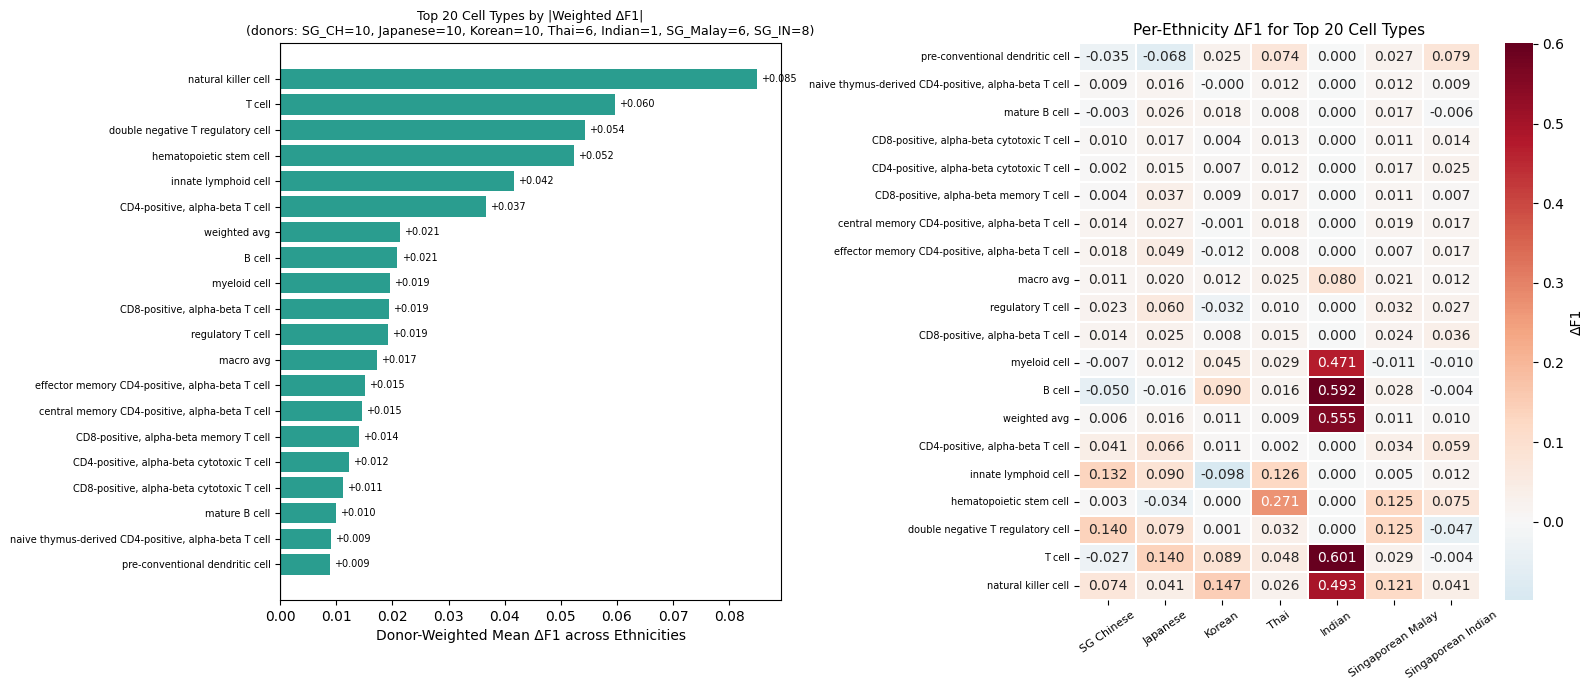

Saved.


In [9]:
# ── Cell 9: Bar Chart — Donor-Weighted ΔF1 per Cell Type ───────────────────
TOP_N = 20

df_plot = df_agg.nlargest(TOP_N, 'abs_weighted').sort_values('weighted_mean')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Left: weighted mean ΔF1 ---
ax = axes[0]
colors = ['#2A9D8F' if v >= 0 else '#E63946' for v in df_plot['weighted_mean']]
bars = ax.barh(df_plot['cell_type'], df_plot['weighted_mean'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.bar_label(bars, fmt='%+.3f', padding=3, fontsize=7)
ax.set_xlabel('Donor-Weighted Mean ΔF1 across Ethnicities', fontsize=10)

# Build weight label for title
wt_parts = []
for lbl, n in n_donors.items():
    short = lbl.replace('SG Chinese','SG_CH').replace('Singaporean Malay','SG_Malay').replace('Singaporean Indian','SG_IN')
    wt_parts.append(f"{short}={n}")
wt_str = ", ".join(wt_parts)
ax.set_title(f'Top {TOP_N} Cell Types by |Weighted ΔF1|\n(donors: {wt_str})', fontsize=9)
ax.tick_params(axis='y', labelsize=7)

# --- Right: per-ethnicity heatmap for these top cells ---
ax2 = axes[1]
import seaborn as sns
top_cts = df_plot['cell_type'].tolist()
pivot_rows = []
for ct in top_cts:
    row = {'cell_type': ct}
    row.update(ct_deltas[ct])
    pivot_rows.append(row)
df_pivot2 = pd.DataFrame(pivot_rows).set_index('cell_type')
df_pivot2 = df_pivot2[[c for c in ETHNICITIES.values() if c in df_pivot2.columns]]

sns.heatmap(
    df_pivot2, annot=True, fmt='.3f', center=0,
    cmap='RdBu_r', linewidths=0.3, ax=ax2,
    cbar_kws={'label': 'ΔF1'},
)
ax2.set_title(f'Per-Ethnicity ΔF1 for Top {TOP_N} Cell Types', fontsize=11)
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.tick_params(axis='x', rotation=35, labelsize=8)
ax2.tick_params(axis='y', labelsize=7)

fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/weighted_delta_celltype_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved.')